# Bird-Predict v2: Coastal Weather and Temporal Validation

This notebook evaluates the `n_records >= 10` GBIF-report target with four coastal KNMI stations, weather-change features, and seasonality. It uses complete held-out calendar years, never random day-level splits. Weather predictors for date *t* are shifted so the latest input is observed on *t-1*; date-*t* seasonality is known in advance. Every imputer, scaler, and estimator is fitted inside its training fold.

**Validation caveat:** requested leave-one-year-out (LOYO) folds train on every year except the test year, including later years. This avoids day-level leakage but is not a forward-in-time deployment simulation. A forward-chaining evaluation should be added before operational claims. GBIF record counts are affected by observer effort and are not confirmed abundance or absences.


**KNMI field note:** in this source, `RH` is daily precipitation (not relative humidity), while `PX` is maximum hourly sea-level pressure. Values retain KNMI scaling. KNMI also cautions that the station series may be inhomogeneous.

In [1]:
from pathlib import Path
import importlib.util

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu
from sklearn.impute import SimpleImputer
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from IPython.display import display, Markdown

ROOT = Path.cwd()
DATA_FILE = ROOT / 'data/processed/bird_predict_dataset_v2.csv'
if not DATA_FILE.is_file():
    raise FileNotFoundError(f'{DATA_FILE} not found. Add KNMI station data and run src/build_dataset_v2.py first.')
data = pd.read_csv(DATA_FILE, parse_dates=['date']).sort_values('date').reset_index(drop=True)
required = {'date', 'n_records', 'influx'}
missing_required = required.difference(data.columns)
if missing_required:
    raise ValueError(f'Dataset is missing required columns: {sorted(missing_required)}')
data['influx'] = (data['n_records'] >= 10).astype(int)
assert data['date'].is_unique, 'Dataset must have one row per date.'
assert not data['date'].duplicated().any()

station_ids = ['235', '242', '225', '310']
station_weather = [f'{v}_{s}' for s in station_ids
                   for v in ['FG', 'FHX', 'TG', 'TN', 'TX', 'RH', 'PX']
                   if f'{v}_{s}' in data.columns]
station_wind = [f'{v}_{s}' for s in station_ids for v in ['wind_sin', 'wind_cos']
                if f'{v}_{s}' in data.columns]
coastal_weather = [c for c in data.columns if c.startswith('coast_')]
temporal_weather = [c for c in data.columns if '_lag_' in c or '_change_' in c]
seasonality = ['month', 'day_of_year', 'day_of_year_sin', 'day_of_year_cos']
missing_seasonality = set(seasonality).difference(data.columns)
if missing_seasonality:
    raise ValueError(f'Missing seasonality columns: {sorted(missing_seasonality)}')
if set(station_ids).difference({c.rsplit('_', 1)[-1] for c in station_weather}):
    raise ValueError('Dataset does not contain weather for all four requested stations.')

station235 = [c for c in station_weather + station_wind if c.endswith('_235')]
coastal_base = station_weather + station_wind + coastal_weather
feature_scenarios = {
    'Station 235 + seasonality': station235 + seasonality,
    'Coastal stations + seasonality': coastal_base + seasonality,
    'Coastal + temporal changes + seasonality': coastal_base + temporal_weather + seasonality,
}
for name, cols in feature_scenarios.items():
    if not cols or len(cols) != len(set(cols)):
        raise ValueError(f'Invalid feature list for {name}.')

weather_columns = sorted(set(station_weather + station_wind + coastal_weather + temporal_weather))
X = data[sorted(set(weather_columns + seasonality))].copy()
X[weather_columns] = X[weather_columns].shift(1)
y = data['influx'].to_numpy()
years = data['date'].dt.year.to_numpy()
print(f'Rows: {len(data):,}; range: {data.date.min().date()} to {data.date.max().date()}')
print(f'Positive days (n_records >= 10): {int(y.sum())} ({y.mean():.2%})')
print(f'Years: {len(np.unique(years))}; station features: {len(station_weather + station_wind)}; coastal: {len(coastal_weather)}; temporal: {len(temporal_weather)}')
print('Missing-value counts for model features:')
display(X.isna().sum().loc[lambda s: s.gt(0)].sort_values(ascending=False).to_frame('missing'))
display(data[['date', 'n_records', 'influx']].loc[data['influx'].eq(1)].head(20))

Rows: 5,793; range: 2010-10-01 to 2026-08-10
Positive days (n_records >= 10): 45 (0.78%)
Years: 17; station features: 36; coastal: 12; temporal: 15
Missing-value counts for model features:


,missing
RH_242,5793
RH_225,5793
PX_225,5793
TN_225,5793
TX_225,5793
...,...
coast_RH_mean,1
wind_cos_235,1
wind_cos_310,1
wind_sin_235,1


,date,n_records,influx
1120,2013-10-25,72,1
1121,2013-10-26,116,1
1128,2013-11-02,158,1
1500,2014-11-09,29,1
1503,2014-11-12,10,1
1504,2014-11-13,13,1
1505,2014-11-14,13,1
1506,2014-11-15,29,1
1864,2015-11-08,114,1
2576,2017-10-20,73,1


## Leave-one-year-out model comparison

The seasonal baseline is a smoothed month-specific event rate. Logistic regression is class-weighted; random forest uses balanced subsampling; XGBoost uses the training-fold negative/positive ratio. Recall, precision, and F1 use a fixed probability threshold of 0.5. PR-AUC is average precision. Metrics are pooled from one out-of-fold prediction per date; ROC-AUC and average precision are undefined for individual test years with no positives.

In [2]:
from xgboost import XGBClassifier

MODEL_NAMES = ['Logistic Regression', 'Random Forest', 'XGBoost']
THRESHOLD = 0.5
fold_models = {}
predictions = {}
fold_rows = []

def make_estimator(name, positive_count, negative_count):
    if positive_count == 0:
        raise ValueError('A training fold has no positive examples.')
    if name == 'Logistic Regression':
        model = LogisticRegression(class_weight='balanced', max_iter=3000, C=0.5)
        steps = [('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
                 ('scale', StandardScaler()), ('model', model)]
    elif name == 'Random Forest':
        model = RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                       class_weight='balanced_subsample',
                                       random_state=42, n_jobs=-1)
        steps = [('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
                 ('model', model)]
    elif name == 'XGBoost':
        model = XGBClassifier(n_estimators=150, max_depth=2, learning_rate=0.05,
                              subsample=0.8, colsample_bytree=0.8,
                              min_child_weight=3, reg_lambda=2,
                              scale_pos_weight=negative_count / positive_count,
                              eval_metric='logloss', n_jobs=1, random_state=42,
                              verbosity=0)
        steps = [('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
                 ('model', model)]
    else:
        raise ValueError(f'Unknown model: {name}')
    return Pipeline(steps)

def pooled_metrics(y_true, probabilities):
    predicted = probabilities >= THRESHOLD
    return {
        'ROC-AUC': roc_auc_score(y_true, probabilities) if np.unique(y_true).size == 2 else np.nan,
        'PR-AUC (AP)': average_precision_score(y_true, probabilities) if np.sum(y_true) else np.nan,
        'Recall @ 0.5': recall_score(y_true, predicted, zero_division=0),
        'Precision @ 0.5': precision_score(y_true, predicted, zero_division=0),
        'F1 @ 0.5': f1_score(y_true, predicted, zero_division=0),
    }

def evaluate_loyo(model_name, feature_list, scenario_name, keep_models=False):
    out_of_fold = np.full(len(data), np.nan)
    saved_models = []
    for year in np.unique(years):
        test = years == year
        train = ~test
        if not y[test].size or not y[train].size:
            continue
        if model_name == 'Seasonal baseline':
            train_frame = data.loc[train, ['month', 'influx']]
            overall_rate = train_frame['influx'].mean()
            month_rates = train_frame.groupby('month')['influx'].agg(['sum', 'count'])
            rates = (month_rates['sum'] + 30 * overall_rate) / (month_rates['count'] + 30)
            out_of_fold[test] = data.loc[test, 'month'].map(rates).fillna(overall_rate).to_numpy()
        else:
            X_train = X.loc[train, feature_list]
            X_test = X.loc[test, feature_list]
            estimator = make_estimator(model_name, int(y[train].sum()), int((1-y[train]).sum()))
            estimator.fit(X_train, y[train])
            out_of_fold[test] = estimator.predict_proba(X_test)[:, 1]
            if keep_models:
                saved_models.append((year, estimator, X_test.copy(), y[test].copy()))
        fold = {'scenario': scenario_name, 'model': model_name, 'test_year': int(year),
                'positive_days': int(y[test].sum()), 'test_days': int(test.sum())}
        fold.update(pooled_metrics(y[test], out_of_fold[test]))
        fold_rows.append(fold)
    if np.isnan(out_of_fold).any():
        raise RuntimeError(f'LOYO did not generate a prediction for every row: {scenario_name}, {model_name}')
    predictions[(scenario_name, model_name)] = out_of_fold
    if keep_models:
        fold_models[(scenario_name, model_name)] = saved_models
    return pooled_metrics(y, out_of_fold)

summary_rows = []
summary_rows.append({'scenario': 'Seasonality only', 'model': 'Seasonal baseline',
                     **evaluate_loyo('Seasonal baseline', seasonality, 'Seasonality only')})
for scenario, feature_list in feature_scenarios.items():
    for model_name in MODEL_NAMES:
        metrics = evaluate_loyo(model_name, feature_list, scenario,
                                keep_models=(scenario == 'Coastal + temporal changes + seasonality'))
        summary_rows.append({'scenario': scenario, 'model': model_name, **metrics})

metrics_table = pd.DataFrame(summary_rows).set_index(['scenario', 'model'])
print('Pooled leave-one-year-out predictions (decision threshold = 0.5):')
display(metrics_table.sort_values('PR-AUC (AP)', ascending=False).round(4))
fold_metrics = pd.DataFrame(fold_rows)
display(fold_metrics.loc[fold_metrics['model'].eq('XGBoost')].pivot(index='test_year', columns='scenario', values='PR-AUC (AP)').round(4))

Pooled leave-one-year-out predictions (decision threshold = 0.5):


ROC-AUC  \
scenario                                 model                          
Station 235 + seasonality                Random Forest         0.9215   
Coastal stations + seasonality           XGBoost               0.9487   
                                         Random Forest         0.9055   
Station 235 + seasonality                XGBoost               0.9412   
Coastal + temporal changes + seasonality Random Forest         0.9482   
                                         XGBoost               0.9452   
Station 235 + seasonality                Logistic Regression   0.9705   
Coastal stations + seasonality           Logistic Regression   0.9633   
Coastal + temporal changes + seasonality Logistic Regression   0.9592   
Seasonality only                         Seasonal baseline     0.9035   

                                                              PR-AUC (AP)  \
scenario                                 model                              
Station 235 + seasonality                Random Forest             0.1721   
Coastal stations + seasonality           XGBoost                   0.1640   
                                         Random Forest             0.1524   
Station 235 + seasonality                XGBoost                   0.1464   
Coastal + temporal changes + seasonality Random Forest             0.1441   
                                         XGBoost                   0.1387   
Station 235 + seasonality                Logistic Regression       0.1379   
Coastal stations + seasonality           Logistic Regression       0.1109   
Coastal + temporal changes + seasonality Logistic Regression       0.1031   
Seasonality only                         Seasonal baseline         0.0416   

                                                              Recall @ 0.5  \
scenario                                 model                               
Station 235 + seasonality                Random Forest              0.1556   
Coastal stations + seasonality           XGBoost                    0.7556   
                                         Random Forest              0.1111   
Station 235 + seasonality                XGBoost                    0.8000   
Coastal + temporal changes + seasonality Random Forest              0.0444   
                                         XGBoost                    0.6889   
Station 235 + seasonality                Logistic Regression        0.9556   
Coastal stations + seasonality           Logistic Regression        0.8667   
Coastal + temporal changes + seasonality Logistic Regression        0.8444   
Seasonality only                         Seasonal baseline          0.0000   

                                                              Precision @ 0.5  \
scenario                                 model                                  
Station 235 + seasonality                Random Forest                 0.1892   
Coastal stations + seasonality           XGBoost                       0.1491   
                                         Random Forest                 0.1724   
Station 235 + seasonality                XGBoost                       0.1463   
Coastal + temporal changes + seasonality Random Forest                 0.1053   
                                         XGBoost                       0.1442   
Station 235 + seasonality                Logistic Regression           0.0790   
Coastal stations + seasonality           Logistic Regression           0.0933   
Coastal + temporal changes + seasonality Logistic Regression           0.0941   
Seasonality only                         Seasonal baseline             0.0000   

                                                              F1 @ 0.5  
scenario                                 model                          
Station 235 + seasonality                Random Forest          0.1707  
Coastal stations + seasonality           XGBoost                0.2491  
                                         Random Forest    

scenario,Coastal + temporal changes + seasonality,Coastal stations + seasonality,Station 235 + seasonality
test_year,,,
2010,NaN,NaN,NaN
2011,NaN,NaN,NaN
2012,NaN,NaN,NaN
2013,0.2296,0.3730,0.1703
2014,0.0797,0.0707,0.0431
2015,0.1111,0.1111,0.0455
2016,NaN,NaN,NaN
2017,0.1250,0.1667,0.1250
2018,0.6667,0.4429,0.6667


## Feature importance and interpretation

The best full-feature model is selected by pooled LOYO average precision. Built-in importance is averaged across training folds; held-out permutation importance measures the change in average precision when a test-year feature is permuted. These rankings are exploratory with few events and correlated weather variables. SHAP is attempted only when the package is installed and a tree model is selected.

Best full-feature model by pooled LOYO AP: Random Forest (0.1441)
Mean fold feature importance:


,mean model importance
feature,
day_of_year,0.145618
day_of_year_sin,0.126610
month,0.111461
day_of_year_cos,0.089115
wind_cos_310,0.054680
coast_wind_cos,0.042012
TG_310,0.039920
wind_cos_225,0.034150
coast_TG_mean,0.028821


Held-out permutation importance (positive values indicate a useful feature):


,mean held-out AP decrease
feature,
day_of_year,0.037430
day_of_year_cos,0.030094
day_of_year_sin,0.026672
wind_cos_225,0.018209
month,0.014229
TN_235,0.011468
wind_cos_310,0.010935
TN_242,0.008967
TG_310,0.008826


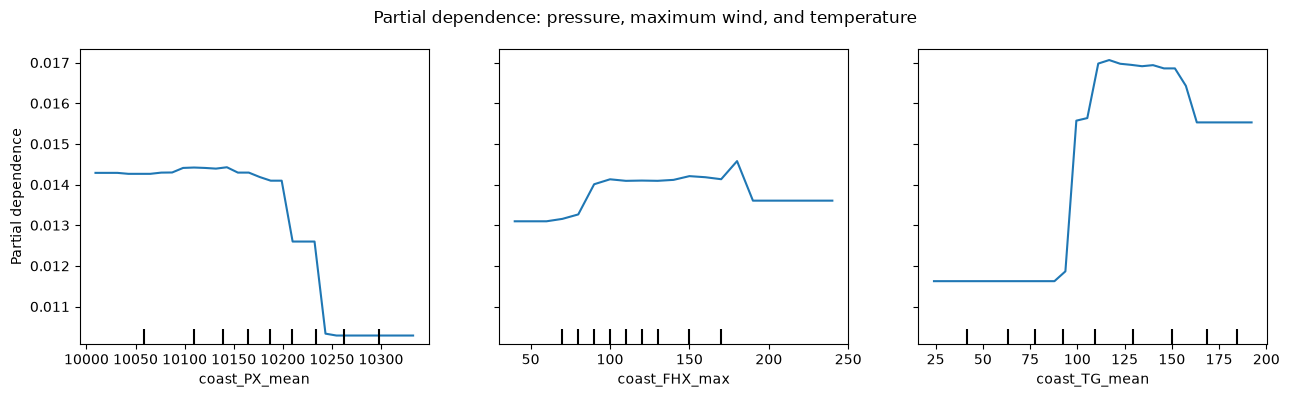

SHAP skipped: shap is not installed.


In [3]:
full_scenario = 'Coastal + temporal changes + seasonality'
full_scores = metrics_table.loc[full_scenario, 'PR-AUC (AP)'].dropna()
best_model_name = full_scores.idxmax()
best_models = fold_models[(full_scenario, best_model_name)]
best_features = feature_scenarios[full_scenario]
print(f'Best full-feature model by pooled LOYO AP: {best_model_name} ({full_scores[best_model_name]:.4f})')

importance_rows = []
permutation_rows = []
for year, estimator, X_test, y_test in best_models:
    fitted = estimator.named_steps['model']
    if hasattr(fitted, 'coef_'):
        values = np.abs(fitted.coef_[0])
    else:
        values = fitted.feature_importances_
    importance_rows.extend({'test_year': year, 'feature': feature, 'importance': float(value)}
                           for feature, value in zip(best_features, values))
    if y_test.sum() > 0:
        result = permutation_importance(estimator, X_test, y_test,
                                        scoring='average_precision', n_repeats=3,
                                        random_state=42, n_jobs=-1)
        permutation_rows.extend({'test_year': year, 'feature': feature,
                                 'importance': float(value)}
                                for feature, value in zip(best_features, result.importances_mean))

importance = (pd.DataFrame(importance_rows).groupby('feature')['importance']
              .mean().sort_values(ascending=False).rename('mean model importance'))
permutation = (pd.DataFrame(permutation_rows).groupby('feature')['importance']
               .mean().sort_values(ascending=False).rename('mean held-out AP decrease'))
print('Mean fold feature importance:')
display(importance.head(20).to_frame())
print('Held-out permutation importance (positive values indicate a useful feature):')
display(permutation.head(20).to_frame())

pdp_features = ['coast_PX_mean', 'coast_FHX_max', 'coast_TG_mean']
if not set(pdp_features).issubset(best_features):
    raise ValueError('Required PDP features are not part of the selected model.')
pdp_model = next((est for _, est, _, _ in best_models), None)
pdp_data = X.loc[:, best_features].dropna(how='all').sample(
    n=min(1000, len(X)), random_state=42)
fig, ax = plt.subplots(figsize=(13, 4))
PartialDependenceDisplay.from_estimator(pdp_model, pdp_data, pdp_features,
                                        ax=ax, kind='average', grid_resolution=30)
fig.suptitle('Partial dependence: pressure, maximum wind, and temperature')
plt.tight_layout()
plt.show()

if importlib.util.find_spec('shap') is None:
    print('SHAP skipped: shap is not installed.')
elif best_model_name == 'Logistic Regression':
    print('SHAP skipped: the selected model is linear; fold-averaged coefficients and permutation importance are reported instead.')
else:
    import shap
    tree_model = best_models[0][1].named_steps['model']
    shap_input = best_models[0][2].sample(n=min(200, len(best_models[0][2])), random_state=42)
    transformed = best_models[0][1].named_steps['imputer'].transform(shap_input)
    explainer = shap.TreeExplainer(tree_model)
    shap_values = explainer.shap_values(transformed)
    shap.summary_plot(shap_values, features=transformed, feature_names=best_features, show=False)
    plt.tight_layout()
    plt.show()

## Biological associations

These same-day contrasts are descriptive association tests, not forecast features or causal effects. Cliff's delta is negative when influx days tend to have lower values. Confidence intervals resample whole years to partially account for serial dependence; the number of year clusters is small, so intervals remain uncertain.

In [4]:
association_features = {
    'Low pressure': ('coast_PX_mean', 'lower'),
    'Pressure drops (24 h)': ('pressure_change_24h', 'lower'),
    'High maximum winds': ('coast_FHX_max', 'higher'),
    'Southerly airflow': (None, 'higher'),
    'Warm conditions': ('coast_TG_mean', 'higher'),
}
data['southerly_flow'] = -data['coast_wind_cos']
association_features['Southerly airflow'] = ('southerly_flow', 'higher')
rng = np.random.default_rng(42)
year_values = np.unique(years)

def cliffs_delta(influx_values, other_values):
    if not len(influx_values) or not len(other_values):
        return np.nan
    u_stat = mannwhitneyu(influx_values, other_values, alternative='two-sided').statistic
    return 2 * u_stat / (len(influx_values) * len(other_values)) - 1

effect_rows = []
for label, (column, expected_direction) in association_features.items():
    values = data[column].to_numpy(dtype=float)
    valid = np.isfinite(values)
    pos = valid & (y == 1)
    neg = valid & (y == 0)
    delta = cliffs_delta(values[pos], values[neg])
    bootstrap = []
    by_year = {year: np.flatnonzero((years == year) & valid) for year in year_values}
    for _ in range(500):
        sampled_years = rng.choice(year_values, size=len(year_values), replace=True)
        sampled_indices = np.concatenate([by_year[year] for year in sampled_years])
        sampled_pos = sampled_indices[y[sampled_indices] == 1]
        sampled_neg = sampled_indices[y[sampled_indices] == 0]
        if len(sampled_pos) and len(sampled_neg):
            bootstrap.append(cliffs_delta(values[sampled_pos], values[sampled_neg]))
    low, high = np.quantile(bootstrap, [0.025, 0.975]) if bootstrap else (np.nan, np.nan)
    consistent = (high < 0) if expected_direction == 'lower' else (low > 0)
    effect_rows.append({'hypothesis': label, 'feature': column,
                        'influx_median': np.nanmedian(values[pos]),
                        'other_median': np.nanmedian(values[neg]),
                        "Cliff's delta": delta, '95% year-bootstrap CI': f'[{low:.3f}, {high:.3f}]',
                        'consistent with expected direction': bool(consistent)})
effects = pd.DataFrame(effect_rows).set_index('hypothesis')
display(effects.round(3))

def biological_summary(row):
    direction = 'lower' if row["Cliff's delta"] < 0 else 'higher'
    supports = row['consistent with expected direction']
    delta = row["Cliff's delta"]
    interval = row['95% year-bootstrap CI']
    interpretation = 'the interval is directionally consistent with the hypothesis.' if supports else 'the interval does not establish the hypothesized direction.'
    return f'{row.name}: influx-day values tend to be {direction} (delta={delta:.2f}, CI {interval}); {interpretation}'

for _, row in effects.iterrows():
    print(biological_summary(row))

,feature,influx_median,other_median,Cliff's delta,95% year-bootstrap CI,consistent with expected direction
hypothesis,,,,,,
Low pressure,coast_PX_mean,10108.333,10185.667,-0.447,"[-0.616, -0.248]",True
Pressure drops (24 h),pressure_change_24h,-0.667,-1.333,-0.043,"[-0.266, 0.175]",False
High maximum winds,coast_FHX_max,130.000,110.000,0.327,"[0.111, 0.583]",True
Southerly airflow,southerly_flow,0.907,0.233,0.655,"[0.568, 0.721]",True
Warm conditions,coast_TG_mean,128.333,108.667,0.164,"[0.024, 0.283]",True


Low pressure: influx-day values tend to be lower (delta=-0.45, CI [-0.616, -0.248]); the interval is directionally consistent with the hypothesis.
Pressure drops (24 h): influx-day values tend to be lower (delta=-0.04, CI [-0.266, 0.175]); the interval does not establish the hypothesized direction.
High maximum winds: influx-day values tend to be higher (delta=0.33, CI [0.111, 0.583]); the interval is directionally consistent with the hypothesis.
Southerly airflow: influx-day values tend to be higher (delta=0.66, CI [0.568, 0.721]); the interval is directionally consistent with the hypothesis.
Warm conditions: influx-day values tend to be higher (delta=0.16, CI [0.024, 0.283]); the interval is directionally consistent with the hypothesis.


## Final report and MVP recommendation

Use the measured LOYO comparisons below to decide whether the expanded station set and change features add information. Do not claim a gain unless it is present in out-of-fold PR-AUC and is reasonably stable across held-out years. This target remains a proxy for reporting intensity.

In [5]:
primary_best_ap = float(full_scores[best_model_name])
baseline_ap = float(metrics_table.loc[('Seasonality only', 'Seasonal baseline'), 'PR-AUC (AP)'])
station_ap = float(metrics_table.loc[('Station 235 + seasonality', best_model_name), 'PR-AUC (AP)'])
coastal_ap = float(metrics_table.loc[('Coastal stations + seasonality', best_model_name), 'PR-AUC (AP)'])
change_gain = primary_best_ap - coastal_ap
station_gain = coastal_ap - station_ap
machine_learning_results = metrics_table.loc[
    metrics_table.index.get_level_values('model') != 'Seasonal baseline'
]
observed_best_configuration = machine_learning_results['PR-AUC (AP)'].idxmax()
observed_best_ap = float(machine_learning_results.loc[observed_best_configuration, 'PR-AUC (AP)'])
print('PR-AUC comparison:')
display(metrics_table['PR-AUC (AP)'].rename('PR-AUC (average precision)').to_frame().round(4))
print(f'For {best_model_name}, multi-station change vs station 235: {station_gain:+.4f} AP.')
print(f'For {best_model_name}, adding temporal changes to coastal weather: {change_gain:+.4f} AP.')
print(f'Highest observed ML configuration: {observed_best_configuration} (AP={observed_best_ap:.4f}); '
      'this is exploratory selection on the same LOYO results, not an independent estimate.')
print('Previously reported single-station MVP AP values (historical context only; not a controlled comparison): '
      'seasonal baseline=0.041, logistic regression=0.141, random forest=0.190.')

if observed_best_ap <= baseline_ap:
    recommendation = ('Do not adopt the weather ML model yet: its pooled LOYO AP does not beat the seasonal baseline. '
                     'Keep the seasonal baseline as the benchmark and improve labels/effort data.')
else:
    recommendation = (f'Treat {observed_best_configuration[1]} with {observed_best_configuration[0]} as the leading '
                     'research MVP configuration, not a deployment-ready model. Confirm it using forward-chaining '
                     'validation; retain the seasonal baseline and calibrate an operational alert threshold using '
                     'training years only.')
print('\nScientific interpretation:')
for _, row in effects.iterrows():
    print('-', biological_summary(row))
print('\nRecommendation:', recommendation)
print('Caveats: GBIF counts conflate biological occurrence with observer effort; consecutive influx days are dependent; '
      'LOYO uses future years in some training folds; one-day weather shift prevents same-day weather leakage but does not '
      'turn LOYO into a prospective test. PDPs and feature rankings are not causal.')
print('Next scientific step: obtain effort-aware observation data (checklist/observer-day covariates), define independent '
      'migration events, and test a pre-registered forward-chaining evaluation with alert-level/event-level metrics.')

PR-AUC comparison:


PR-AUC (average precision)
scenario                                 model                                          
Seasonality only                         Seasonal baseline                        0.0416
Station 235 + seasonality                Logistic Regression                      0.1379
                                         Random Forest                            0.1721
                                         XGBoost                                  0.1464
Coastal stations + seasonality           Logistic Regression                      0.1109
                                         Random Forest                            0.1524
                                         XGBoost                                  0.1640
Coastal + temporal changes + seasonality Logistic Regression                      0.1031
                                         Random Forest                            0.1441
                                         XGBoost                                  0.1387

For Random Forest, multi-station change vs station 235: -0.0197 AP.
For Random Forest, adding temporal changes to coastal weather: -0.0083 AP.
Highest observed ML configuration: ('Station 235 + seasonality', 'Random Forest') (AP=0.1721); this is exploratory selection on the same LOYO results, not an independent estimate.
Previously reported single-station MVP AP values (historical context only; not a controlled comparison): seasonal baseline=0.041, logistic regression=0.141, random forest=0.190.

Scientific interpretation:
- Low pressure: influx-day values tend to be lower (delta=-0.45, CI [-0.616, -0.248]); the interval is directionally consistent with the hypothesis.
- Pressure drops (24 h): influx-day values tend to be lower (delta=-0.04, CI [-0.266, 0.175]); the interval does not establish the hypothesized direction.
- High maximum winds: influx-day values tend to be higher (delta=0.33, CI [0.111, 0.583]); the interval is directionally consistent with the hypothesis.
- Southerly ai